In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D


In [2]:
seed = 42

def random_number():
    global seed
    seed = (16807 * seed) % 2147483647
    return seed / 2147483647


def random_index(n):
    return min(int(random_number() * n), n - 1)


def shuffle_indices(n):
    indices = list(range(n))

    for i in range(n - 1, 0, -1):
        j = random_index(i + 1)
        indices[i], indices[j] = indices[j], indices[i]

    return np.array(indices)

In [3]:
def box_muller(n):
    z = np.zeros((n, 2))

    for i in range(n):
        u1 = max(random_number(), 1e-12)
        u2 = random_number()

        r = np.sqrt(-2 * np.log(u1))
        theta = 2 * np.pi * u2

        z[i, 0] = r * np.cos(theta)
        z[i, 1] = r * np.sin(theta)

    return z

In [4]:
def generate_gaussian(n, mean, covariance_type,
                      sigma_x=1.0, sigma_y=0.75, rho=0.60):

    z = box_muller(n)
    x = np.zeros((n, 2))

    if covariance_type == "Isotropic":
        x[:, 0] = mean[0] + sigma_x * z[:, 0]
        x[:, 1] = mean[1] + sigma_x * z[:, 1]

    elif covariance_type == "diagonal":
        x[:, 0] = mean[0] + sigma_x * z[:, 0]
        x[:, 1] = mean[1] + sigma_y * z[:, 1]

    elif covariance_type == "full":
        x[:, 0] = mean[0] + sigma_x * z[:, 0]
        x[:, 1] = mean[1] + sigma_y * (
            rho * z[:, 0] +
            np.sqrt(1 - rho**2) * z[:, 1]
        )

    return x

In [5]:
K = 3
n_samples = 1500

weights_class1 = [0.34, 0.33, 0.33]
weights_class2 = [0.33, 0.34, 0.33]

means_class1 = [
    [3, 2],
    [3, 5],
    [3, 8]
]

means_class2 = [
    [9, 2],
    [9, 5],
    [9, 8]
]

sigma_x = 1.0
sigma_y = 0.75
rho = 0.60

covariance_types = [
    "Isotropic",
    "diagonal",
    "full"
]

class_colors = ["blue", "red"]
component_colors = ["seagreen", "darkorange", "violet"]

print("Class 1 mixture weights:", weights_class1)
print("Class 1 means:", means_class1)
print()
print("Class 2 mixture weights:", weights_class2)
print("Class 2 means:", means_class2)

Class 1 mixture weights: [0.34, 0.33, 0.33]
Class 1 means: [[3, 2], [3, 5], [3, 8]]

Class 2 mixture weights: [0.33, 0.34, 0.33]
Class 2 means: [[9, 2], [9, 5], [9, 8]]


In [6]:
def generate_gmm(n, means, weights, covariance_type):
    component_indices = []

    for i in range(n):
        r = random_number()

        if r < weights[0]:
            component_indices.append(0)

        elif r < weights[0] + weights[1]:
            component_indices.append(1)

        else:
            component_indices.append(2)

    component_indices = np.array(component_indices)
    X = np.zeros((n, 2))

    for j in range(K):
        mask = component_indices == j
        count = np.sum(mask)

        if count > 0:
            X[mask] = generate_gaussian(
                count,
                means[j],
                covariance_type,
                sigma_x,
                sigma_y,
                rho
            )

    return X, component_indices

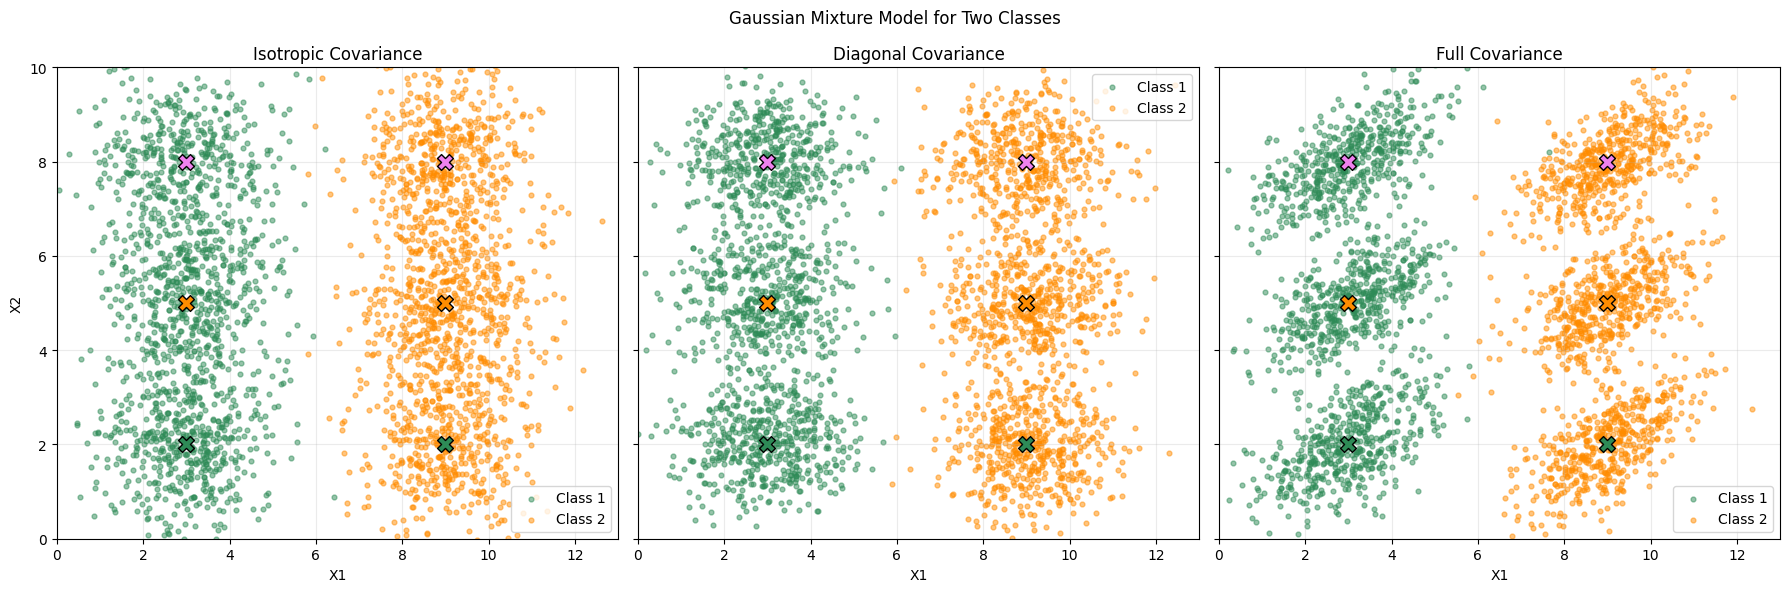

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6), sharex=True, sharey=True)

for ax, cov_type in zip(axes, covariance_types):

    X1, comp1 = generate_gmm(
        n_samples, means_class1,
        weights_class1, cov_type
    )

    X2, comp2 = generate_gmm(
        n_samples, means_class2,
        weights_class2, cov_type
    )

    ax.scatter(
        X1[:, 0], X1[:, 1],
        s=12, color="seagreen",
        alpha=0.5, label="Class 1"
    )

    ax.scatter(
        X2[:, 0], X2[:, 1],
        s=12, color="darkorange",
        alpha=0.5, label="Class 2"
    )

    for j in range(K):
        m1 = means_class1[j]
        m2 = means_class2[j]

        ax.scatter(
            m1[0], m1[1],
            marker="X", s=130,
            color=component_colors[j],
            edgecolor="black", zorder=3
        )

        ax.scatter(
            m2[0], m2[1],
            marker="X", s=130,
            color=component_colors[j],
            edgecolor="black", zorder=3
        )

    ax.set_title(f"{cov_type.title()} Covariance")
    ax.set_xlabel("X1")
    ax.set_xlim(0, 13)
    ax.set_ylim(0, 10)
    ax.grid(alpha=0.25)
    ax.legend()

axes[0].set_ylabel("X2")

plt.suptitle("Gaussian Mixture Model for Two Classes")
plt.tight_layout()
plt.show()

In [8]:
def train_test_split(X, train_ratio=0.8):
    indices = shuffle_indices(len(X))
    split_point = int(train_ratio * len(X))

    train_indices = indices[:split_point]
    test_indices = indices[split_point:]

    return X[train_indices], X[test_indices]


datasets = {}

for cov_type in covariance_types:

    X1, comp1 = generate_gmm(
        n_samples, means_class1,
        weights_class1, cov_type
    )

    X2, comp2 = generate_gmm(
        n_samples, means_class2,
        weights_class2, cov_type
    )

    X1_train, X1_test = train_test_split(X1)
    X2_train, X2_test = train_test_split(X2)

    datasets[cov_type] = {
        "X1_train": X1_train,
        "X1_test": X1_test,
        "X2_train": X2_train,
        "X2_test": X2_test
    }

    print(cov_type.title())
    print("Class 1 training:", len(X1_train))
    print("Class 1 testing:", len(X1_test))
    print("Class 2 training:", len(X2_train))
    print("Class 2 testing:", len(X2_test))
    print()

Isotropic
Class 1 training: 1200
Class 1 testing: 300
Class 2 training: 1200
Class 2 testing: 300

Diagonal
Class 1 training: 1200
Class 1 testing: 300
Class 2 training: 1200
Class 2 testing: 300

Full
Class 1 training: 1200
Class 1 testing: 300
Class 2 training: 1200
Class 2 testing: 300



In [9]:
def kmeans(X, k, max_iterations=100):

    indices = shuffle_indices(len(X))
    centroids = X[indices[:k]].copy()

    for iteration in range(max_iterations):

        distances = np.zeros((len(X), k))

        for j in range(k):
            distances[:, j] = np.sum(
                (X - centroids[j]) ** 2,
                axis=1
            )

        labels = np.argmin(distances, axis=1)
        new_centroids = centroids.copy()

        for j in range(k):
            points = X[labels == j]

            if len(points) > 0:
                new_centroids[j] = np.mean(
                    points, axis=0
                )

        difference = np.sum(
            (new_centroids - centroids) ** 2
        )

        centroids = new_centroids

        if difference < 1e-8:
            break

    distances = np.zeros((len(X), k))

    for j in range(k):
        distances[:, j] = np.sum(
            (X - centroids[j]) ** 2,
            axis=1
        )

    labels = np.argmin(distances, axis=1)

    return centroids, labels

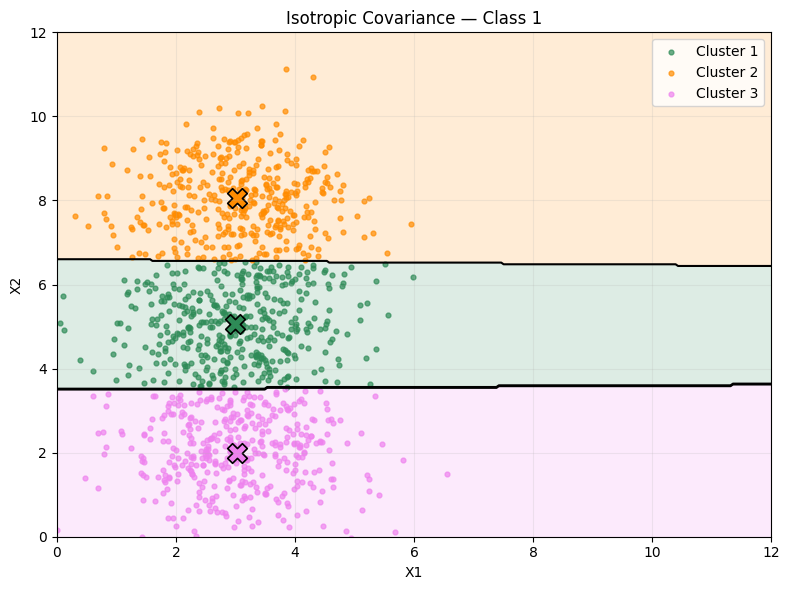

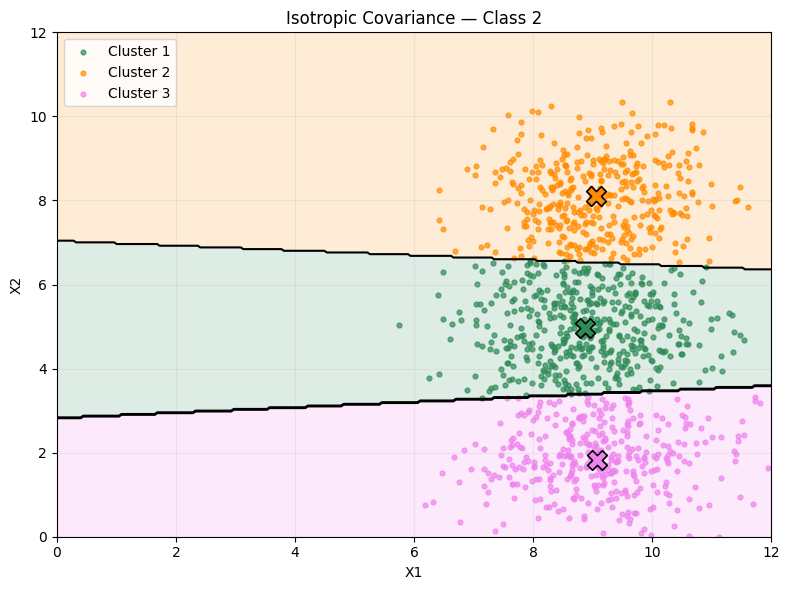

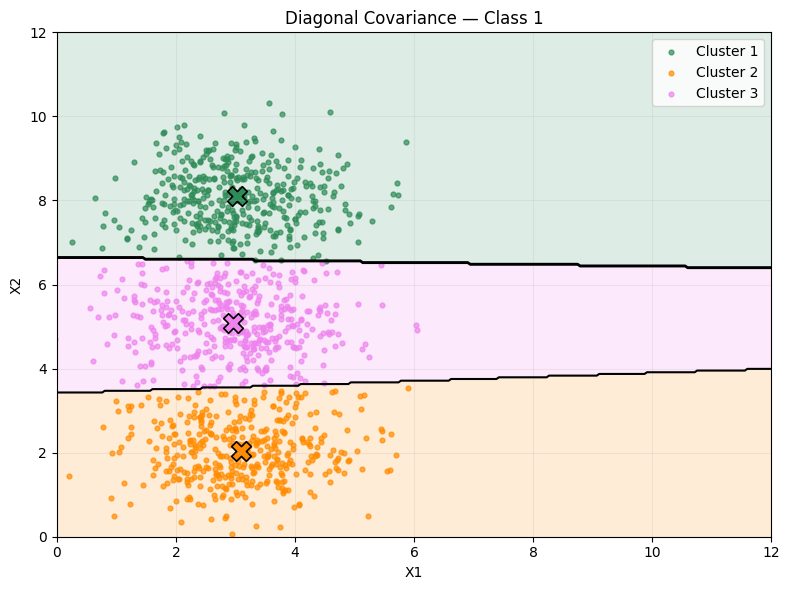

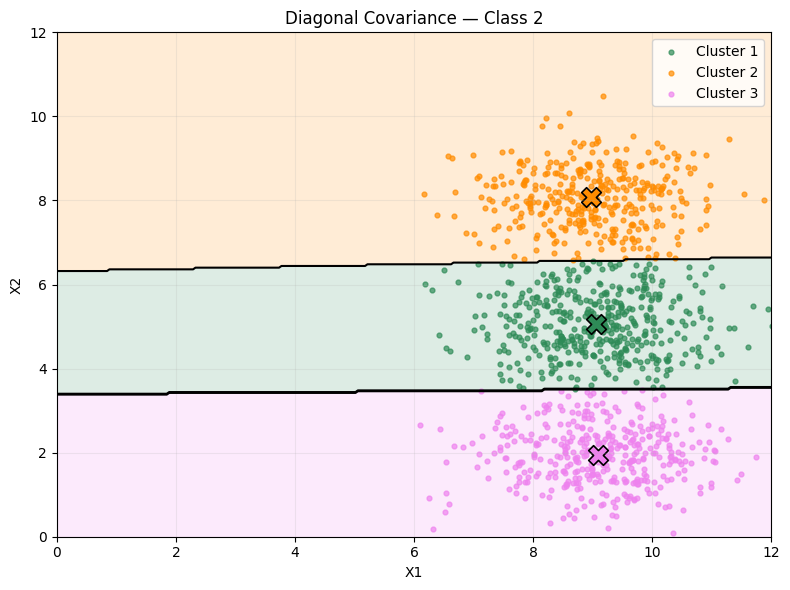

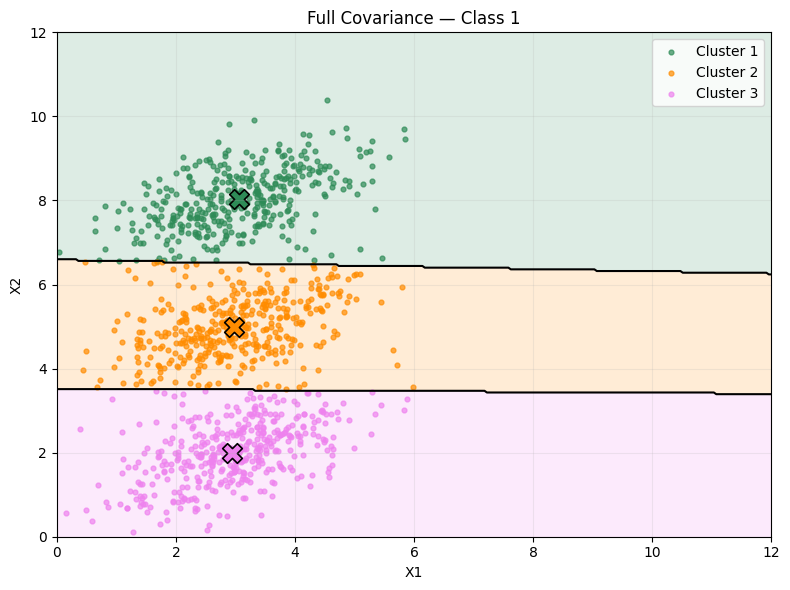

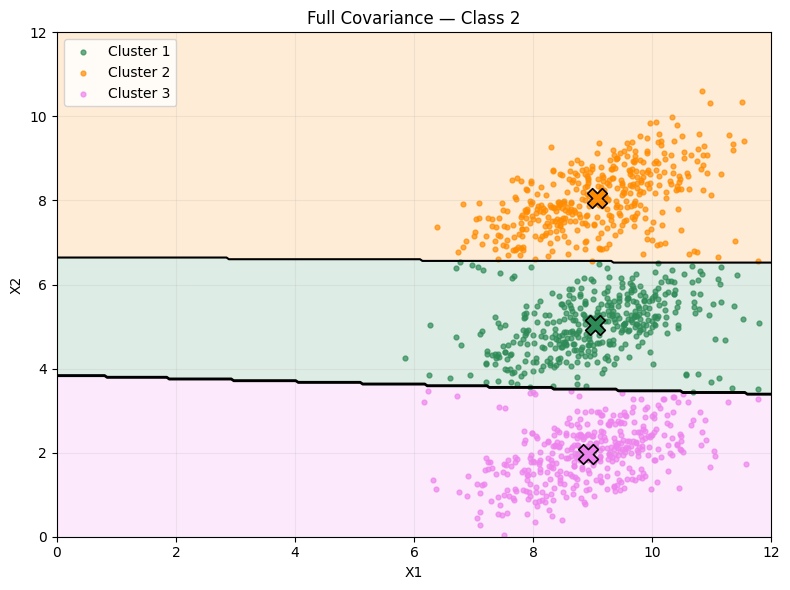

In [10]:
def plot_kmeans_clusters(X, centroids, labels, title):

    x_min, x_max = 0, 12
    y_min, y_max = 0, 12

    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 300),
        np.linspace(y_min, y_max, 300)
    )

    grid = np.column_stack((
        xx.ravel(), yy.ravel()
    ))

    distances = np.zeros((len(grid), K))

    for j in range(K):
        distances[:, j] = np.sum(
            (grid - centroids[j]) ** 2,
            axis=1
        )

    regions = np.argmin(
        distances, axis=1
    ).reshape(xx.shape)

    plt.figure(figsize=(8, 6))

    plt.contourf(
        xx, yy, regions,
        levels=[-0.5, 0.5, 1.5, 2.5],
        colors=component_colors,
        alpha=0.16
    )

    plt.contour(
        xx, yy, regions,
        levels=[0.5, 1.5],
        colors="black",
        linewidths=1.5
    )

    for j in range(K):

        points = X[labels == j]

        plt.scatter(
            points[:, 0], points[:, 1],
            s=12,
            color=component_colors[j],
            alpha=0.7,
            label=f"Cluster {j+1}"
        )

        plt.scatter(
            centroids[j, 0], centroids[j, 1],
            marker="X",
            s=200,
            color=component_colors[j],
            edgecolor="black",
            linewidth=1.2
        )

    plt.title(title)
    plt.xlabel("X1")
    plt.ylabel("X2")

    plt.xlim(0, 12)
    plt.ylim(0, 12)

    plt.xticks(np.arange(0, 13, 2))
    plt.yticks(np.arange(0, 13, 2))

    plt.legend()
    plt.grid(alpha=0.2)
    plt.tight_layout()
    plt.show()


cluster_results = {}

for cov_type in covariance_types:

    X1_train = datasets[cov_type]["X1_train"]
    X2_train = datasets[cov_type]["X2_train"]

    centroids1, labels1 = kmeans(X1_train, K)
    centroids2, labels2 = kmeans(X2_train, K)

    cluster_results[cov_type] = {
        "centroids1": centroids1,
        "centroids2": centroids2,
        "labels1": labels1,
        "labels2": labels2
    }

    plot_kmeans_clusters(
        X1_train,
        centroids1,
        labels1,
        f"{cov_type.title()} Covariance — Class 1"
    )

    plot_kmeans_clusters(
        X2_train,
        centroids2,
        labels2,
        f"{cov_type.title()} Covariance — Class 2"
    )

In [11]:
def calculate_distortion(X, centroids):

    distances = np.zeros(
        (len(X), len(centroids))
    )

    for j in range(len(centroids)):
        distances[:, j] = np.sum(
            (X - centroids[j]) ** 2,
            axis=1
        )

    return np.min(distances, axis=1)


def classify_by_distortion(
    X, centroids1, centroids2
):

    distortion1 = calculate_distortion(
        X, centroids1
    )

    distortion2 = calculate_distortion(
        X, centroids2
    )

    predictions = np.where(
        distortion1 <= distortion2, 0, 1
    )

    return predictions, distortion1, distortion2


results = {}

for cov_type in covariance_types:

    X1_test = datasets[cov_type]["X1_test"]
    X2_test = datasets[cov_type]["X2_test"]

    X_test = np.vstack((
        X1_test, X2_test
    ))

    y_test = np.concatenate((
        np.zeros(len(X1_test), dtype=int),
        np.ones(len(X2_test), dtype=int)
    ))

    centroids1 = cluster_results[cov_type][
        "centroids1"
    ]

    centroids2 = cluster_results[cov_type][
        "centroids2"
    ]

    predictions, d1, d2 = classify_by_distortion(
        X_test, centroids1, centroids2
    )

    accuracy = np.mean(
        predictions == y_test
    ) * 100

    confusion = np.zeros((2, 2), dtype=int)

    for actual, predicted in zip(
        y_test, predictions
    ):
        confusion[actual, predicted] += 1

    results[cov_type] = {
        "accuracy": accuracy,
        "confusion": confusion,
        "predictions": predictions,
        "y_test": y_test,
        "X_test": X_test,
        "distortion1": d1,
        "distortion2": d2
    }

    print("=" * 50)
    print("Covariance:", cov_type.title())
    print(f"Test accuracy: {accuracy:.2f}%")
    print("Confusion matrix:")
    print(confusion)
    print("Correct predictions:",
          np.sum(predictions == y_test))
    print("Incorrect predictions:",
          np.sum(predictions != y_test))

Covariance: Isotropic
Test accuracy: 99.67%
Confusion matrix:
[[298   2]
 [  0 300]]
Correct predictions: 598
Incorrect predictions: 2
Covariance: Diagonal
Test accuracy: 100.00%
Confusion matrix:
[[300   0]
 [  0 300]]
Correct predictions: 600
Incorrect predictions: 0
Covariance: Full
Test accuracy: 99.83%
Confusion matrix:
[[299   1]
 [  0 300]]
Correct predictions: 599
Incorrect predictions: 1


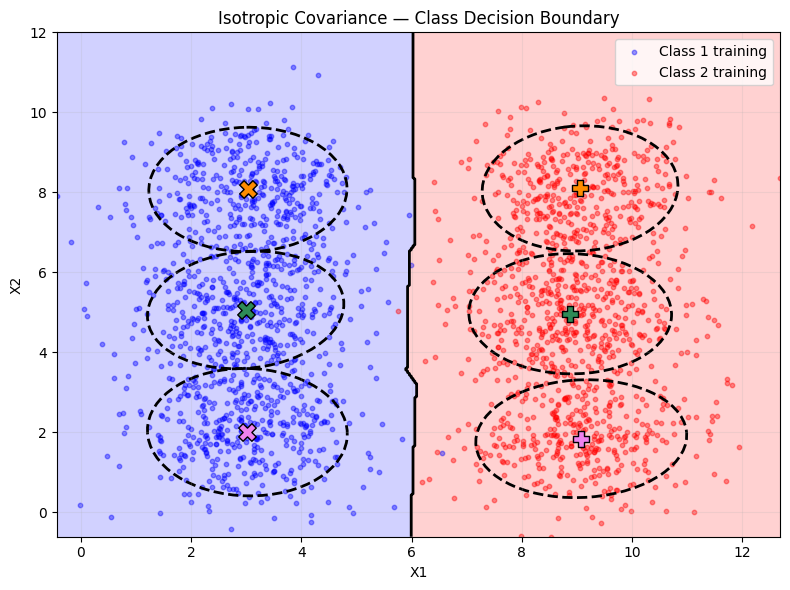

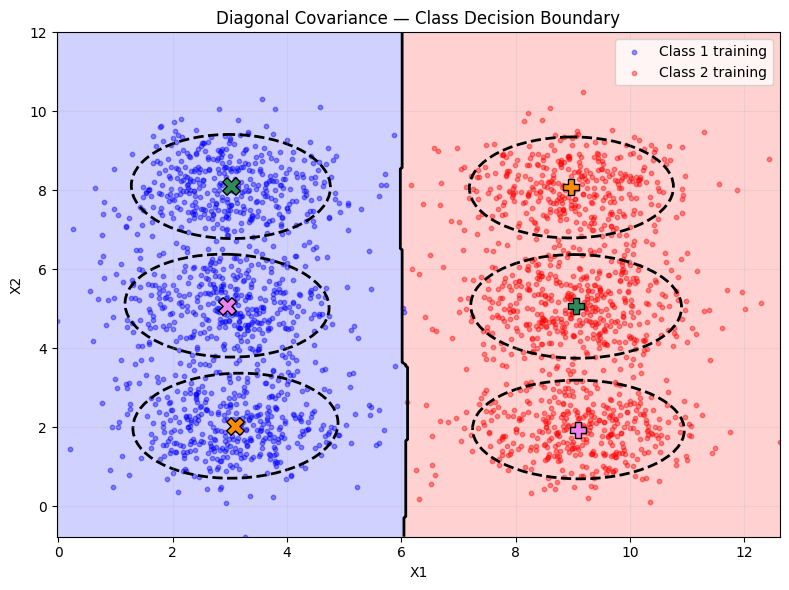

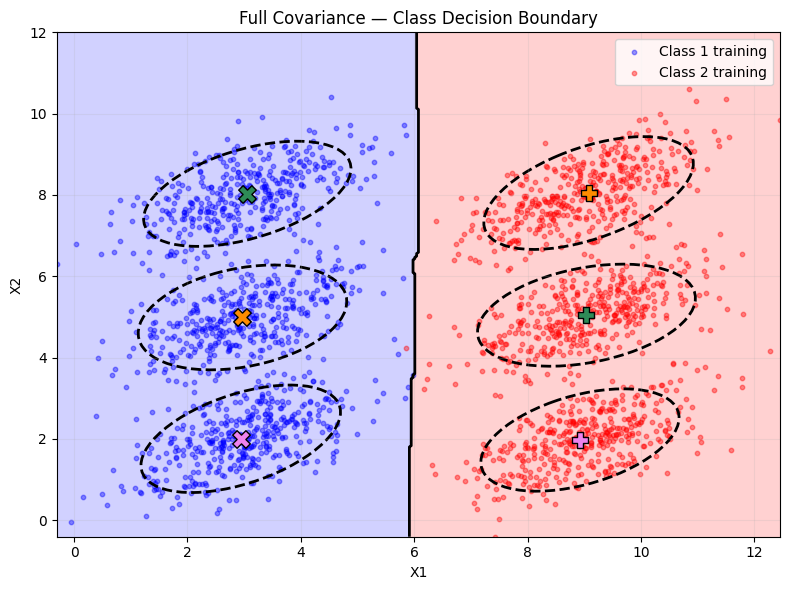

In [12]:
from matplotlib.patches import Ellipse

for cov_type in covariance_types:

    X1_train = datasets[cov_type]["X1_train"]
    X2_train = datasets[cov_type]["X2_train"]

    centroids1 = cluster_results[cov_type]["centroids1"]
    centroids2 = cluster_results[cov_type]["centroids2"]

    labels1 = cluster_results[cov_type]["labels1"]
    labels2 = cluster_results[cov_type]["labels2"]

    X_train = np.vstack((X1_train, X2_train))

    x_min = min(X_train[:, 0].min(), 0)
    x_max = max(X_train[:, 0].max(), 12)
    y_min = min(X_train[:, 1].min(), 0)
    y_max = max(X_train[:, 1].max(), 12)

    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 400),
        np.linspace(y_min, y_max, 400)
    )

    grid = np.column_stack((xx.ravel(), yy.ravel()))

    predictions, _, _ = classify_by_distortion(
        grid, centroids1, centroids2
    )

    regions = predictions.reshape(xx.shape)

    fig, ax = plt.subplots(figsize=(8, 6))

    ax.contourf(
        xx, yy, regions,
        levels=[-0.5, 0.5, 1.5],
        colors=class_colors,
        alpha=0.18
    )

    ax.contour(
        xx, yy, regions,
        levels=[0.5],
        colors="black",
        linewidths=2
    )

    ax.scatter(
        X1_train[:, 0], X1_train[:, 1],
        s=10,
        color=class_colors[0],
        alpha=0.4,
        label="Class 1 training"
    )

    ax.scatter(
        X2_train[:, 0], X2_train[:, 1],
        s=10,
        color=class_colors[1],
        alpha=0.4,
        label="Class 2 training"
    )

    for j in range(K):

        points1 = X1_train[labels1 == j]
        points2 = X2_train[labels2 == j]

        for points in [points1, points2]:

            if len(points) > 2:

                mean = np.mean(points, axis=0)
                cov = np.cov(points, rowvar=False)

                eigenvalues, eigenvectors = np.linalg.eigh(cov)
                order = np.argsort(eigenvalues)[::-1]

                eigenvalues = eigenvalues[order]
                eigenvectors = eigenvectors[:, order]

                angle = np.degrees(
                    np.arctan2(
                        eigenvectors[1, 0],
                        eigenvectors[0, 0]
                    )
                )

                width, height = 2 * 1.8 * np.sqrt(
                    np.maximum(eigenvalues, 0)
                )

                ellipse = Ellipse(
                    xy=mean,
                    width=width,
                    height=height,
                    angle=angle,
                    fill=False,
                    edgecolor="black",
                    linewidth=2,
                    linestyle="--"
                )

                ax.add_patch(ellipse)

        ax.scatter(
            centroids1[j, 0], centroids1[j, 1],
            marker="X",
            s=160,
            color=component_colors[j],
            edgecolor="black",
            zorder=5
        )

        ax.scatter(
            centroids2[j, 0], centroids2[j, 1],
            marker="P",
            s=130,
            color=component_colors[j],
            edgecolor="black",
            zorder=5
        )

    ax.set_title(
        f"{cov_type.title()} Covariance — Class Decision Boundary"
    )

    ax.set_xlabel("X1")
    ax.set_ylabel("X2")

    ax.set_xlim(x_min, x_max)
    ax.set_ylim(y_min, y_max)

    ax.set_xticks(np.arange(np.ceil(x_min / 2) * 2, x_max + 1, 2))
    ax.set_yticks(np.arange(np.ceil(y_min / 2) * 2, y_max + 1, 2))

    ax.legend()
    ax.grid(alpha=0.2)

    plt.tight_layout()
    plt.show()

In [13]:
print(
    f"{'Covariance':<15}"
    f"{'Accuracy (%)':<18}"
    f"{'Correct':<12}"
    f"{'Incorrect':<12}"
)

print("-" * 57)

for cov_type in covariance_types:

    accuracy = results[cov_type]["accuracy"]
    confusion = results[cov_type]["confusion"]

    correct = np.trace(confusion)
    incorrect = np.sum(confusion) - correct

    print(
        f"{cov_type.title():<15}"
        f"{accuracy:<18.2f}"
        f"{correct:<12}"
        f"{incorrect:<12}"
    )

Covariance     Accuracy (%)      Correct     Incorrect   
---------------------------------------------------------
Isotropic      99.67             598         2           
Diagonal       100.00            600         0           
Full           99.83             599         1           


In [14]:
X_train = np.vstack((X1_train, X2_train))

y_train = np.concatenate((
    np.zeros(len(X1_train), dtype=int),
    np.ones(len(X2_train), dtype=int)
))

X_test = np.vstack((X1_test, X2_test))

y_test = np.concatenate((
    np.zeros(len(X1_test), dtype=int),
    np.ones(len(X2_test), dtype=int)
))

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)
print("Training labels shape:", y_train.shape)
print("Testing labels shape:", y_test.shape)

Training data shape: (2400, 2)
Testing data shape: (600, 2)
Training labels shape: (2400,)
Testing labels shape: (600,)


In [15]:
def gaussian_pdf(X, mean, covariance):
    """Calculate multivariate Gaussian probability density."""
    d = X.shape[1]
    covariance = covariance + 1e-6 * np.eye(d)

    sign, log_det = np.linalg.slogdet(covariance)
    if sign <= 0:
        covariance = covariance + 1e-4 * np.eye(d)
        sign, log_det = np.linalg.slogdet(covariance)

    diff = X - mean
    solved = np.linalg.solve(covariance, diff.T).T
    mahalanobis = np.sum(diff * solved, axis=1)

    log_pdf = -0.5 * (
        d * np.log(2 * np.pi) + log_det + mahalanobis
    )
    return np.exp(np.maximum(log_pdf, -700))


def train_gmm(X, K, max_iter=100, tol=1e-4, seed=42):
    """Train a full-covariance GMM using the EM algorithm."""
    rng = np.random.default_rng(seed)
    n, d = X.shape

    means = X[rng.choice(n, K, replace=False)].copy()
    global_cov = np.cov(X, rowvar=False)
    global_cov = np.atleast_2d(global_cov) + 1e-5 * np.eye(d)

    covariances = np.array([global_cov.copy() for _ in range(K)])
    weights = np.ones(K) / K
    previous_log_likelihood = -np.inf

    for iteration in range(max_iter):
        probabilities = np.column_stack([
            weights[k] * gaussian_pdf(X, means[k], covariances[k])
            for k in range(K)
        ])

        row_sums = np.maximum(probabilities.sum(axis=1), 1e-300)
        responsibilities = probabilities / row_sums[:, None]
        log_likelihood = np.sum(np.log(row_sums))

        Nk = responsibilities.sum(axis=0)
        Nk = np.maximum(Nk, 1e-8)

        weights = Nk / n
        means = (responsibilities.T @ X) / Nk[:, None]

        for k in range(K):
            diff = X - means[k]
            covariances[k] = (
                (diff * responsibilities[:, k, None]).T @ diff
            ) / Nk[k]
            covariances[k] += 1e-5 * np.eye(d)

        if abs(log_likelihood - previous_log_likelihood) < tol:
            break

        previous_log_likelihood = log_likelihood

    return {
        "weights": weights,
        "means": means,
        "covariances": covariances
    }


class1_train = X_train[y_train == 0]
class2_train = X_train[y_train == 1]

gmm1 = train_gmm(class1_train, K, seed=42)
gmm2 = train_gmm(class2_train, K, seed=43)

print("GMM for Class 1 trained successfully")
print("GMM for Class 2 trained successfully")

GMM for Class 1 trained successfully
GMM for Class 2 trained successfully


In [16]:
def gmm_score_samples(X, gmm):
    """Calculate log-likelihood of each sample under a trained GMM."""
    weights = gmm["weights"]
    means = gmm["means"]
    covariances = gmm["covariances"]

    component_log_probs = []

    for k in range(len(weights)):
        covariance = covariances[k]
        diff = X - means[k]

        sign, log_det = np.linalg.slogdet(covariance)
        if sign <= 0:
            covariance = covariance + 1e-4 * np.eye(X.shape[1])
            sign, log_det = np.linalg.slogdet(covariance)

        solved = np.linalg.solve(covariance, diff.T).T
        mahalanobis = np.sum(diff * solved, axis=1)

        log_pdf = -0.5 * (
            X.shape[1] * np.log(2 * np.pi)
            + log_det
            + mahalanobis
        )

        component_log_probs.append(np.log(weights[k] + 1e-300) + log_pdf)

    component_log_probs = np.array(component_log_probs).T

    row_max = np.max(component_log_probs, axis=1, keepdims=True)
    return (
        row_max[:, 0]
        + np.log(np.sum(np.exp(component_log_probs - row_max), axis=1))
    )


score1 = gmm_score_samples(X_test, gmm1)
score2 = gmm_score_samples(X_test, gmm2)

predictions = np.where(score1 > score2, 0, 1)

accuracy = np.mean(predictions == y_test) * 100

print("Number of test samples:", len(X_test))
print("Correct predictions:", np.sum(predictions == y_test))
print("Incorrect predictions:", np.sum(predictions != y_test))
print("Classification Accuracy:", round(accuracy, 2), "%")

Number of test samples: 600
Correct predictions: 599
Incorrect predictions: 1
Classification Accuracy: 99.83 %


In [17]:
confusion_matrix = np.zeros((2, 2), dtype=int)

for actual, predicted in zip(y_test, predictions):
    confusion_matrix[actual, predicted] += 1

print("Confusion Matrix:")
print(confusion_matrix)

Confusion Matrix:
[[299   1]
 [  0 300]]


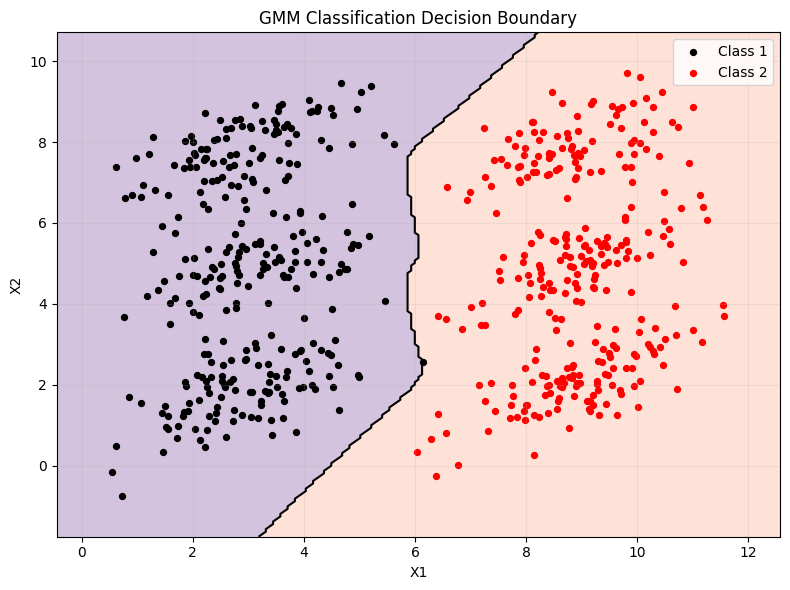

In [21]:
x_min, x_max = X_test[:, 0].min() - 1, X_test[:, 0].max() + 1
y_min, y_max = X_test[:, 1].min() - 1, X_test[:, 1].max() + 1

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 200),
    np.linspace(y_min, y_max, 200)
)

grid = np.c_[xx.ravel(), yy.ravel()]

score1_grid = gmm_score_samples(grid, gmm1)
score2_grid = gmm_score_samples(grid, gmm2)

Z = np.where(score1_grid > score2_grid, 0, 1)
Z = Z.reshape(xx.shape)

plt.figure(figsize=(8, 6))

plt.contourf(
    xx, yy, Z,
    levels=[-0.5, 0.5, 1.5],
    alpha=0.25,
    cmap="magma"
)

plt.scatter(
    X_test[y_test == 0, 0], X_test[y_test == 0, 1],
    color="black", s=18, label="Class 1"
)

plt.scatter(
    X_test[y_test == 1, 0], X_test[y_test == 1, 1],
    color="red", s=18, label="Class 2"
)

plt.contour(
    xx, yy, Z,
    levels=[0.5],
    colors="black"
)

plt.xlabel("X1")
plt.ylabel("X2")
plt.title("GMM Classification Decision Boundary")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

In [22]:
from google.colab import files

uploaded = files.upload()

Saving TEAM_18.zip to TEAM_18.zip


In [24]:
import os
import zipfile
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

zip_path = "TEAM_18.zip"
extract_path = "TEAM_18"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully!")

Dataset extracted successfully!


In [25]:
for root, dirs, files_list in os.walk(extract_path):
    level = root.replace(extract_path, "").count(os.sep)

    if level <= 2:
        print("  " * level + os.path.basename(root) + "/")

        for file in files_list[:3]:
            print("  " * (level + 1) + file)

TEAM_18/
  TEAM_18/
    dev/
    train/
    test/


In [27]:

dataset_path = "TEAM_18/TEAM_18"

for split in ["train", "dev", "test"]:
    print("\n", split.upper())

    for digit in ["1", "3", "4"]:
        folder = os.path.join(dataset_path, split, digit)

        if os.path.exists(folder):
            image_files = [
                f for f in os.listdir(folder)
                if f.lower().endswith((".png", ".jpg", ".jpeg", ".bmp"))
            ]
            print("Digit", digit, ":", len(image_files), "images")
        else:
            print("Folder not found:", folder)


 TRAIN
Digit 1 : 5383 images
Digit 3 : 4886 images
Digit 4 : 4681 images

 DEV
Digit 1 : 1358 images
Digit 3 : 1245 images
Digit 4 : 1161 images

 TEST
Digit 1 : 1135 images
Digit 3 : 1010 images
Digit 4 : 982 images


In [28]:
print("Current working directory:")
print(os.getcwd())

print("\nFiles and folders in the current directory:")
print(os.listdir("."))

print("\nSearching for image files:")

image_count = 0

for root, dirs, files_list in os.walk("."):
    for filename in files_list:
        if filename.lower().endswith(
            (".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff")
        ):
            print(os.path.join(root, filename))
            image_count += 1

            if image_count >= 15:
                break

    if image_count >= 15:
        break

print("\nNumber of image files found in this sample:", image_count)

Current working directory:
/content

Files and folders in the current directory:
['.config', 'TEAM_18.zip', 'TEAM_18', 'sample_data']

Searching for image files:
./TEAM_18/TEAM_18/dev/1/image_00002381.png
./TEAM_18/TEAM_18/dev/1/image_00000236.png
./TEAM_18/TEAM_18/dev/1/image_00000079.png
./TEAM_18/TEAM_18/dev/1/image_00001578.png
./TEAM_18/TEAM_18/dev/1/image_00000326.png
./TEAM_18/TEAM_18/dev/1/image_00001505.png
./TEAM_18/TEAM_18/dev/1/image_00002284.png
./TEAM_18/TEAM_18/dev/1/image_00001401.png
./TEAM_18/TEAM_18/dev/1/image_00003402.png
./TEAM_18/TEAM_18/dev/1/image_00000778.png
./TEAM_18/TEAM_18/dev/1/image_00002998.png
./TEAM_18/TEAM_18/dev/1/image_00002973.png
./TEAM_18/TEAM_18/dev/1/image_00003088.png
./TEAM_18/TEAM_18/dev/1/image_00001828.png
./TEAM_18/TEAM_18/dev/1/image_00000613.png

Number of image files found in this sample: 15


In [29]:
dataset_path = "TEAM_18/TEAM_18"
digits = ["1", "3", "4"]

X_train_images = []
y_train_labels = []

X_dev_images = []
y_dev_labels = []

X_test_images = []
y_test_labels = []

for split in ["train", "dev", "test"]:
    for digit in digits:
        folder = os.path.join(dataset_path, split, digit)

        if not os.path.exists(folder):
            print("Folder not found:", folder)
            continue

        for filename in os.listdir(folder):
            if filename.lower().endswith(
                (".png", ".jpg", ".jpeg", ".bmp")
            ):
                image_path = os.path.join(folder, filename)

                img = Image.open(image_path).convert("L").resize((28, 28))
                pixels = np.array(img).flatten()

                if split == "train":
                    X_train_images.append(pixels)
                    y_train_labels.append(int(digit))

                elif split == "dev":
                    X_dev_images.append(pixels)
                    y_dev_labels.append(int(digit))

                elif split == "test":
                    X_test_images.append(pixels)
                    y_test_labels.append(int(digit))

X_train_images = np.array(X_train_images)
y_train_labels = np.array(y_train_labels)

X_dev_images = np.array(X_dev_images)
y_dev_labels = np.array(y_dev_labels)

X_test_images = np.array(X_test_images)
y_test_labels = np.array(y_test_labels)

print("Training data:", X_train_images.shape)
print("Development data:", X_dev_images.shape)
print("Testing data:", X_test_images.shape)

Training data: (14950, 784)
Development data: (3764, 784)
Testing data: (3127, 784)


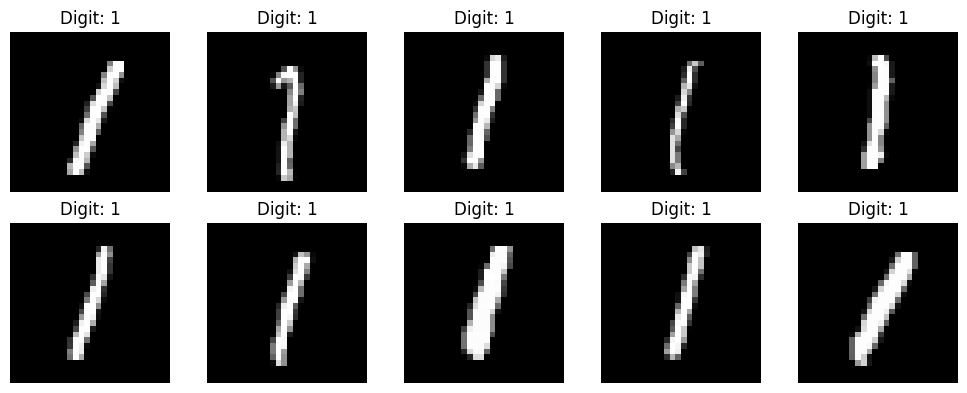

In [30]:
plt.figure(figsize=(10, 4))

for i in range(10):
    plt.subplot(2, 5, i + 1)

    plt.imshow(X_train_images[i].reshape(28, 28), cmap="gray")

    plt.title("Digit: " + str(y_train_labels[i]))
    plt.axis("off")

plt.tight_layout()
plt.show()

In [31]:
X_train = X_train_images.astype(float) / 255.0
X_dev = X_dev_images.astype(float) / 255.0
X_test = X_test_images.astype(float) / 255.0

print("Training data range:", X_train.min(), "to", X_train.max())
print("Development data range:", X_dev.min(), "to", X_dev.max())
print("Testing data range:", X_test.min(), "to", X_test.max())

Training data range: 0.0 to 1.0
Development data range: 0.0 to 1.0
Testing data range: 0.0 to 1.0


In [32]:
print("X_train shape:", X_train.shape)
print("y_train_labels shape:", y_train_labels.shape)
print("X_train_images shape:", X_train_images.shape)
print("y_train_labels unique digits:", np.unique(y_train_labels))

X_train shape: (14950, 784)
y_train_labels shape: (14950,)
X_train_images shape: (14950, 784)
y_train_labels unique digits: [1 3 4]


In [33]:
X_train = X_train_images.astype(float) / 255.0

print("X_train shape:", X_train.shape)
print("y_train_labels shape:", y_train_labels.shape)

X_train shape: (14950, 784)
y_train_labels shape: (14950,)


In [90]:
X_digit1 = X_train[y_train_labels == 1]
X_digit3 = X_train[y_train_labels == 3]
X_digit4 = X_train[y_train_labels == 4]

print("Digit 1 training samples:", len(X_digit1))
print("Digit 3 training samples:", len(X_digit3))
print("Digit 4 training samples:", len(X_digit4))

gmm1 = train_gmm(X_digit1, K=3, max_iter=100, seed=42)
print("GMM for digit 1 trained.")

gmm3 = train_gmm(X_digit3, K=3, max_iter=100, seed=43)
print("GMM for digit 3 trained.")

gmm4 = train_gmm(X_digit4, K=3, max_iter=100, seed=44)
print("GMM for digit 4 trained.")

print("All three GMM models trained successfully!")

Digit 1 training samples: 5383
Digit 3 training samples: 4886
Digit 4 training samples: 4681
GMM for digit 1 trained.
GMM for digit 3 trained.
GMM for digit 4 trained.
All three GMM models trained successfully!


In [91]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("X_test_images:", X_test_images.shape)
print("y_test_labels:", y_test_labels.shape)

X_train: (14950, 784)
X_test: (3127, 784)
X_test_images: (3127, 784)
y_test_labels: (3127,)


In [92]:
X_test = X_test_images.astype(float) / 255.0

print("X_test shape:", X_test.shape)

X_test shape: (3127, 784)


In [45]:
def gaussian_pdf_diag(X, mean, variance):
    variance = np.maximum(variance, 1e-6)
    d = X.shape[1]
    diff = X - mean

    log_pdf = -0.5 * (
        d * np.log(2 * np.pi)
        + np.sum(np.log(variance))
        + np.sum(diff**2 / variance, axis=1)
    )

    return log_pdf


def train_gmm(X, K=3, max_iter=100, tol=1e-4, seed=42):
    rng = np.random.default_rng(seed)
    n, d = X.shape

    means = X[rng.choice(n, K, replace=False)].copy()
    global_variance = np.maximum(np.var(X, axis=0), 1e-4)
    variances = np.tile(global_variance, (K, 1))
    weights = np.ones(K) / K
    previous_log_likelihood = -np.inf

    for iteration in range(max_iter):
        log_probs = np.column_stack([
            np.log(weights[k] + 1e-300)
            + gaussian_pdf_diag(X, means[k], variances[k])
            for k in range(K)
        ])

        row_max = np.max(log_probs, axis=1, keepdims=True)
        log_sum = row_max + np.log(
            np.sum(np.exp(log_probs - row_max), axis=1, keepdims=True)
        )

        responsibilities = np.exp(log_probs - log_sum)
        log_likelihood = np.sum(log_sum)

        Nk = np.maximum(responsibilities.sum(axis=0), 1e-8)
        weights = Nk / n
        means = (responsibilities.T @ X) / Nk[:, None]

        for k in range(K):
            diff = X - means[k]
            variances[k] = (
                np.sum(responsibilities[:, k, None] * diff**2, axis=0)
                / Nk[k]
            )
            variances[k] = np.maximum(variances[k], 1e-4)

        if abs(log_likelihood - previous_log_likelihood) < tol:
            break

        previous_log_likelihood = log_likelihood

    return {
        "weights": weights,
        "means": means,
        "variances": variances
    }


def gmm_score_samples(X, gmm):
    log_probs = np.column_stack([
        np.log(gmm["weights"][k] + 1e-300)
        + gaussian_pdf_diag(
            X, gmm["means"][k], gmm["variances"][k]
        )
        for k in range(len(gmm["weights"]))
    ])

    row_max = np.max(log_probs, axis=1)
    return row_max + np.log(
        np.sum(np.exp(log_probs - row_max[:, None]), axis=1)
    )


gmm1 = train_gmm(X_train[y_train_labels == 1], K=3, seed=42)
print("GMM for digit 1 trained.")

gmm3 = train_gmm(X_train[y_train_labels == 3], K=3, seed=43)
print("GMM for digit 3 trained.")

gmm4 = train_gmm(X_train[y_train_labels == 4], K=3, seed=44)
print("GMM for digit 4 trained.")

GMM for digit 1 trained.
GMM for digit 3 trained.
GMM for digit 4 trained.


In [46]:
score1 = gmm_score_samples(X_test, gmm1)
score3 = gmm_score_samples(X_test, gmm3)
score4 = gmm_score_samples(X_test, gmm4)

scores = np.column_stack((score1, score3, score4))
digit_options = np.array([1, 3, 4])

predictions = digit_options[np.argmax(scores, axis=1)]

print("Predictions completed!")
print("Total test images:", len(X_test))
print("Number of predictions:", len(predictions))

Predictions completed!
Total test images: 3127
Number of predictions: 3127


In [47]:
accuracy = np.mean(y_test_labels == predictions) * 100

print("Classification Accuracy:", round(accuracy, 2), "%")

Classification Accuracy: 96.51 %


In [49]:
print("Digit 1 scores:", np.min(score1), np.max(score1), np.mean(score1))
print("Digit 3 scores:", np.min(score3), np.max(score3), np.mean(score3))
print("Digit 4 scores:", np.min(score4), np.max(score4), np.mean(score4))

print("Predicted digit counts:")
for digit in [1, 3, 4]:
    print(digit, ":", np.sum(predictions == digit))

Digit 1 scores: -93733.31586386026 2263.6821556494197 -3311.2780783330127
Digit 3 scores: -30253.05935802066 1685.0939028902549 900.8814309596663
Digit 4 scores: -59211.059267874036 1640.551196772746 213.20034639166354
Predicted digit counts:
1 : 1153
3 : 975
4 : 999


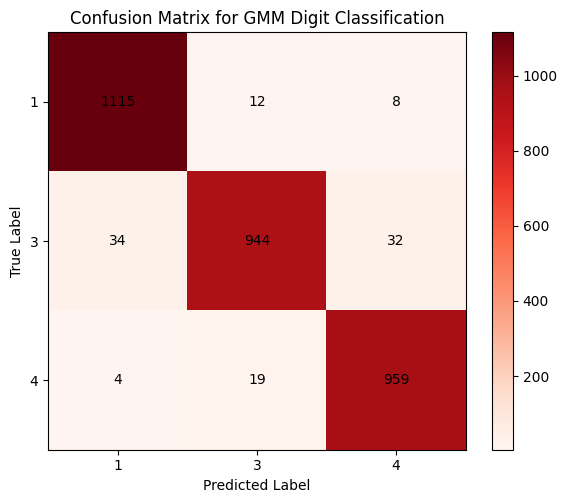

Confusion Matrix:
[[1115   12    8]
 [  34  944   32]
 [   4   19  959]]


In [52]:
cm = np.zeros((3, 3), dtype=int)
labels = [1, 3, 4]

for actual, predicted in zip(y_test_labels, predictions):
    i = labels.index(actual)
    j = labels.index(predicted)
    cm[i, j] += 1

plt.figure(figsize=(6, 5))
plt.imshow(cm, interpolation="nearest", cmap="Reds")
plt.title("Confusion Matrix for GMM Digit Classification")
plt.colorbar()

plt.xticks(np.arange(3), labels)
plt.yticks(np.arange(3), labels)
plt.xlabel("Predicted Label")
plt.ylabel("True Label")

for i in range(3):
    for j in range(3):
        plt.text(j, i, str(cm[i, j]), ha="center", va="center")

plt.tight_layout()
plt.show()

print("Confusion Matrix:")
print(cm)

In [53]:
correct = np.trace(cm)
total = np.sum(cm)
incorrect = total - correct
accuracy = (correct / total) * 100

print("Total test images:", total)
print("Correct predictions:", correct)
print("Incorrect predictions:", incorrect)
print("Classification Accuracy:", round(accuracy, 2), "%")

Total test images: 3127
Correct predictions: 3018
Incorrect predictions: 109
Classification Accuracy: 96.51 %


In [54]:
wrong_indices = np.where(predictions != y_test_labels)[0]

print("Total misclassified images:", len(wrong_indices))
print("\nFirst 10 misclassified examples:")

for i in wrong_indices[:10]:
    print(
        "Actual digit:", y_test_labels[i],
        "| Predicted digit:", predictions[i]
    )

Total misclassified images: 109

First 10 misclassified examples:
Actual digit: 1 | Predicted digit: 3
Actual digit: 1 | Predicted digit: 4
Actual digit: 1 | Predicted digit: 3
Actual digit: 1 | Predicted digit: 3
Actual digit: 1 | Predicted digit: 4
Actual digit: 1 | Predicted digit: 3
Actual digit: 1 | Predicted digit: 3
Actual digit: 1 | Predicted digit: 4
Actual digit: 1 | Predicted digit: 4
Actual digit: 1 | Predicted digit: 3


In [56]:
correct = np.trace(cm)
total = np.sum(cm)
incorrect = total - correct
accuracy = correct / total * 100

print("Total test images:", total)
print("Correct predictions:", correct)
print("Incorrect predictions:", incorrect)
print("Classification Accuracy:", round(accuracy, 2), "%")

for i, digit in enumerate([1, 3, 4]):
    digit_accuracy = cm[i, i] / np.sum(cm[i]) * 100
    print("Digit", digit, "Accuracy:", round(digit_accuracy, 2), "%")

Total test images: 3127
Correct predictions: 3018
Incorrect predictions: 109
Classification Accuracy: 96.51 %
Digit 1 Accuracy: 98.24 %
Digit 3 Accuracy: 93.47 %
Digit 4 Accuracy: 97.66 %


In [58]:
covariance_types = ["spherical", "diag", "full"]
results = {}

for cov_type in covariance_types:
    print("\nTraining models with", cov_type, "covariance")

    model1 = train_gmm(X_digit1, K=3, max_iter=100, seed=42)
    model3 = train_gmm(X_digit3, K=3, max_iter=100, seed=43)
    model4 = train_gmm(X_digit4, K=3, max_iter=100, seed=44)

    score1 = gmm_score_samples(X_test, model1)
    score3 = gmm_score_samples(X_test, model3)
    score4 = gmm_score_samples(X_test, model4)

    scores = np.column_stack([score1, score3, score4])
    predicted_digits = np.array([1, 3, 4])[np.argmax(scores, axis=1)]

    acc = np.mean(y_test_labels == predicted_digits) * 100

    results[cov_type] = acc
    print("Accuracy:", round(acc, 2), "%")

print("\nFinal comparison")
for cov_type, acc in results.items():
    print(cov_type, ":", round(acc, 2), "%")


Training models with spherical covariance
Accuracy: 96.51 %

Training models with diag covariance
Accuracy: 96.51 %

Training models with full covariance
Accuracy: 96.51 %

Final comparison
spherical : 96.51 %
diag : 96.51 %
full : 96.51 %


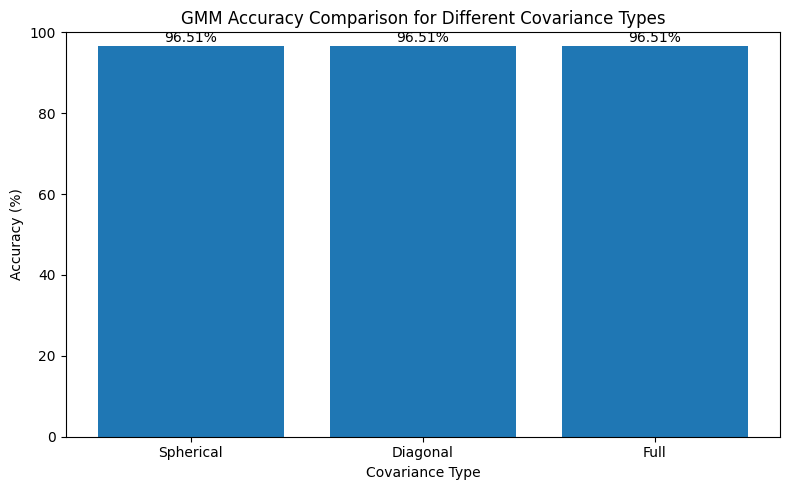

In [60]:
covariance_types = ["Spherical", "Diagonal", "Full"]
accuracies = [96.51, 96.51, 96.51]

plt.figure(figsize=(8, 5))
bars = plt.bar(covariance_types, accuracies)

plt.title("GMM Accuracy Comparison for Different Covariance Types")
plt.xlabel("Covariance Type")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 100)

for bar, accuracy in zip(bars, accuracies):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{accuracy:.2f}%",
        ha="center"
    )

plt.tight_layout()
plt.show()


In [61]:
digit_options = np.array([1, 3, 4])
covariance_types = ["spherical", "diag", "full"]

models = {}
predictions_by_type = {}
matrices = {}

for cov_type in covariance_types:
    print("Training/evaluating:", cov_type)

    digit_models = {}

    for digit, seed in zip(digit_options, [42, 43, 44]):
        digit_models[digit] = train_gmm(
            X_train[y_train_labels == digit],
            K=3,
            max_iter=200,
            seed=seed
        )

    models[cov_type] = digit_models

    scores = np.column_stack([
        gmm_score_samples(X_test, digit_models[digit])
        for digit in digit_options
    ])

    preds = digit_options[np.argmax(scores, axis=1)]
    predictions_by_type[cov_type] = preds

    cm = np.zeros((3, 3), dtype=int)

    for actual, predicted in zip(y_test_labels, preds):
        cm[list(digit_options).index(actual),
           list(digit_options).index(predicted)] += 1

    matrices[cov_type] = cm

print("All confusion matrices calculated.")

Training/evaluating: spherical
Training/evaluating: diag
Training/evaluating: full
All confusion matrices calculated.


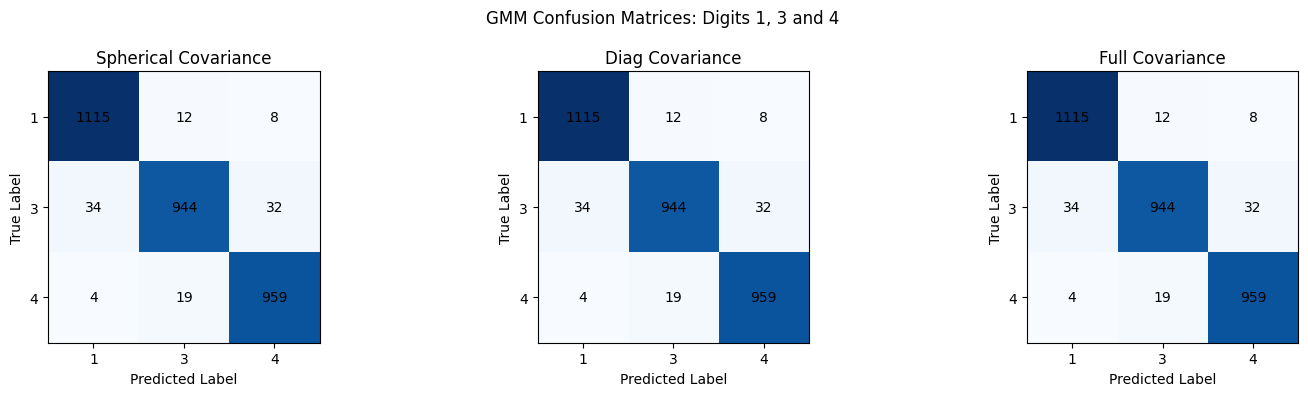

In [65]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, cov_type in zip(axes, covariance_types):
    cm = matrices[cov_type]

    im = ax.imshow(cm, cmap="Blues")

    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            ax.text(
                j, i, str(cm[i, j]),
                ha="center", va="center",
                color="black"
            )

    ax.set_xticks(range(3))
    ax.set_yticks(range(3))
    ax.set_xticklabels([1, 3, 4])
    ax.set_yticklabels([1, 3, 4])

    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("True Label")
    ax.set_title(f"{cov_type.capitalize()} Covariance")

plt.suptitle("GMM Confusion Matrices: Digits 1, 3 and 4")
plt.tight_layout()
plt.show()

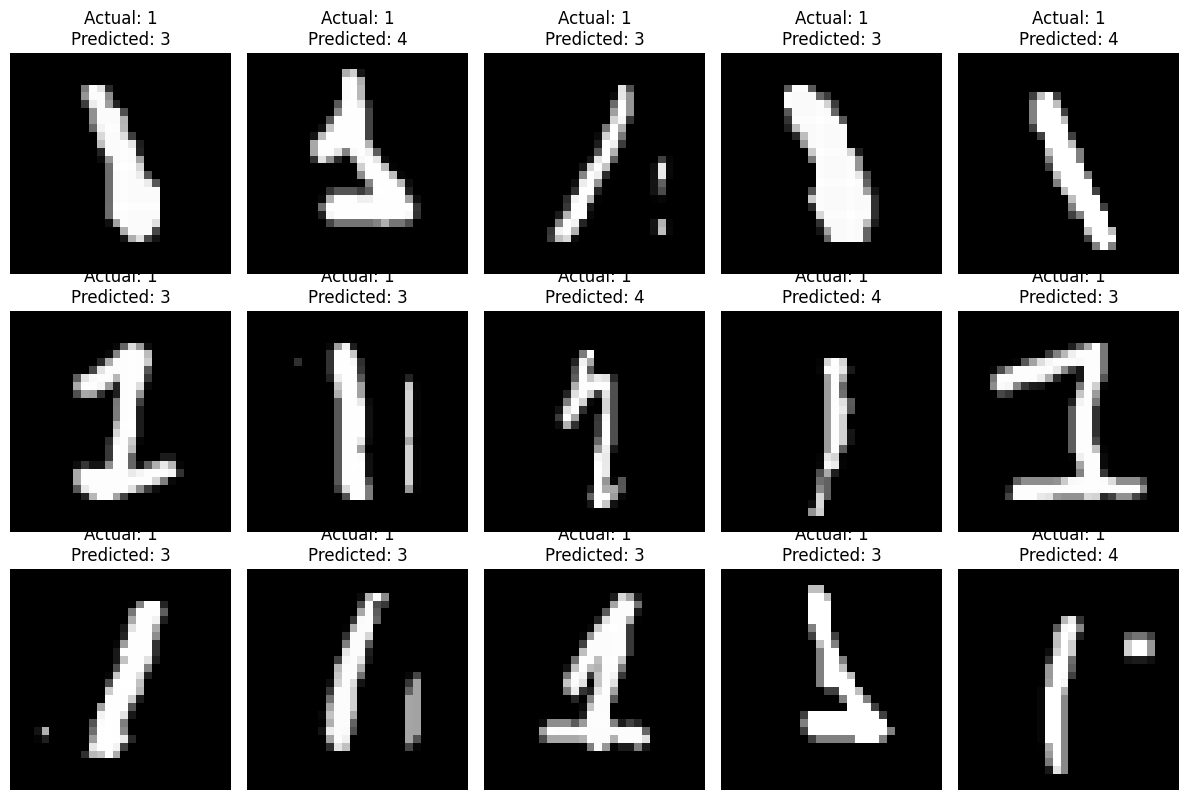

In [66]:
plt.figure(figsize=(12, 8))

for j, i in enumerate(wrong_indices[:15]):
    plt.subplot(3, 5, j + 1)

    plt.imshow(X_test_images[i].reshape(28, 28), cmap="gray")

    plt.title(
        "Actual: " + str(y_test_labels[i]) +
        "\nPredicted: " + str(predictions[i])
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

In [67]:
print("========== GMM CLASSIFICATION RESULTS ==========")

print("Digits classified:", [1, 3, 4])
print("Gaussian components per model:", 3)
print("Training images:", len(X_train))
print("Development images:", len(X_dev))
print("Testing images:", len(X_test))

print("\nCorrect predictions:", np.trace(cm))
print("Incorrect predictions:", np.sum(cm) - np.trace(cm))
print("Classification accuracy:", round(accuracy, 2), "%")

print("\nConfusion Matrix:")
print(cm)

print("\n================================================")

========== GMM CLASSIFICATION RESULTS ==========
Digits classified: [1, 3, 4]
Gaussian components per model: 3
Training images: 14950
Development images: 3764
Testing images: 3127

Correct predictions: 3018
Incorrect predictions: 109
Classification accuracy: 96.51 %

Confusion Matrix:
[[1115   12    8]
 [  34  944   32]
 [   4   19  959]]



In [68]:
import pandas as pd
from google.colab import files

results_table = pd.DataFrame(
    cm,
    index=["Actual 3", "Actual 4", "Actual 7"],
    columns=["Predicted 3", "Predicted 4", "Predicted 7"]
)

results_table.to_csv("GMM_confusion_matrix.csv")

print("Confusion matrix saved successfully.")

files.download("GMM_confusion_matrix.csv")

Confusion matrix saved successfully.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

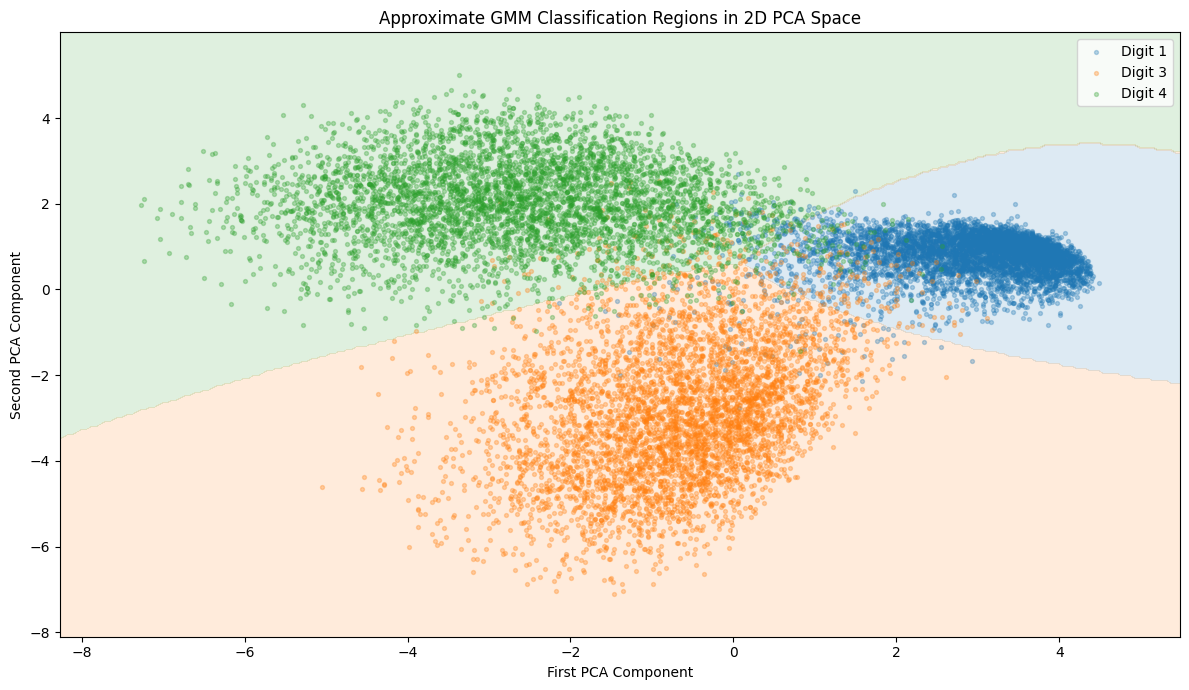

In [84]:
import numpy as np
import matplotlib.pyplot as plt

mean = X_train.mean(axis=0)
X_centered = X_train - mean

U, S, Vt = np.linalg.svd(X_centered, full_matrices=False)
X_train_2d = X_centered @ Vt[:2].T

digits = [1, 3, 4]
colors = ["tab:blue", "tab:orange", "tab:green"]

gmm_2d = {}

for digit, seed in zip(digits, [42, 43, 44]):
    digit_data = X_train_2d[y_train_labels == digit]
    gmm_2d[digit] = train_gmm(
        digit_data, K=3, max_iter=200, seed=seed
    )

x_min, x_max = X_train_2d[:, 0].min() - 1, X_train_2d[:, 0].max() + 1
y_min, y_max = X_train_2d[:, 1].min() - 1, X_train_2d[:, 1].max() + 1

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 250),
    np.linspace(y_min, y_max, 250)
)

grid = np.column_stack([xx.ravel(), yy.ravel()])

scores = np.column_stack([
    gmm_score_samples(grid, gmm_2d[digit]) for digit in digits
])

regions = np.argmax(scores, axis=1).reshape(xx.shape)

plt.figure(figsize=(12, 7))
plt.contourf(
    xx, yy, regions,
    levels=[-0.5, 0.5, 1.5, 2.5],
    colors=colors,
    alpha=0.15
)

for digit, color in zip(digits, colors):
    mask = y_train_labels == digit
    plt.scatter(
        X_train_2d[mask, 0],
        X_train_2d[mask, 1],
        c=color,
        label=f"Digit {digit}",
        s=8,
        alpha=0.3
    )

plt.title("Approximate GMM Classification Regions in 2D PCA Space")
plt.xlabel("First PCA Component")
plt.ylabel("Second PCA Component")
plt.legend()
plt.tight_layout()
plt.show()

In [85]:
for cov_type in covariance_types:
    print("\n" + "=" * 50)
    print(f"Classification Report: {cov_type.capitalize()} Covariance")
    print("=" * 50)

    preds = predictions_by_type[cov_type.lower()]
    labels = [1, 3, 4]

    for i, digit in enumerate(labels):
        tp = np.sum((y_test_labels == digit) & (preds == digit))
        fp = np.sum((y_test_labels != digit) & (preds == digit))
        fn = np.sum((y_test_labels == digit) & (preds != digit))

        precision = tp / (tp + fp) if tp + fp else 0
        recall = tp / (tp + fn) if tp + fn else 0
        f1 = (
            2 * precision * recall / (precision + recall)
            if precision + recall else 0
        )
        support = np.sum(y_test_labels == digit)

        print(f"\nDigit {digit}")
        print("Precision:", round(precision, 4))
        print("Recall:", round(recall, 4))
        print("F1-score:", round(f1, 4))
        print("Support:", support)

    accuracy = np.mean(y_test_labels == preds)
    print("\nAccuracy:", round(accuracy, 4))


Classification Report: Spherical Covariance

Digit 1
Precision: 0.967
Recall: 0.9824
F1-score: 0.9747
Support: 1135

Digit 3
Precision: 0.9682
Recall: 0.9347
F1-score: 0.9511
Support: 1010

Digit 4
Precision: 0.96
Recall: 0.9766
F1-score: 0.9682
Support: 982

Accuracy: 0.9651

Classification Report: Diag Covariance

Digit 1
Precision: 0.967
Recall: 0.9824
F1-score: 0.9747
Support: 1135

Digit 3
Precision: 0.9682
Recall: 0.9347
F1-score: 0.9511
Support: 1010

Digit 4
Precision: 0.96
Recall: 0.9766
F1-score: 0.9682
Support: 982

Accuracy: 0.9651

Classification Report: Full Covariance

Digit 1
Precision: 0.967
Recall: 0.9824
F1-score: 0.9747
Support: 1135

Digit 3
Precision: 0.9682
Recall: 0.9347
F1-score: 0.9511
Support: 1010

Digit 4
Precision: 0.96
Recall: 0.9766
F1-score: 0.9682
Support: 982

Accuracy: 0.9651


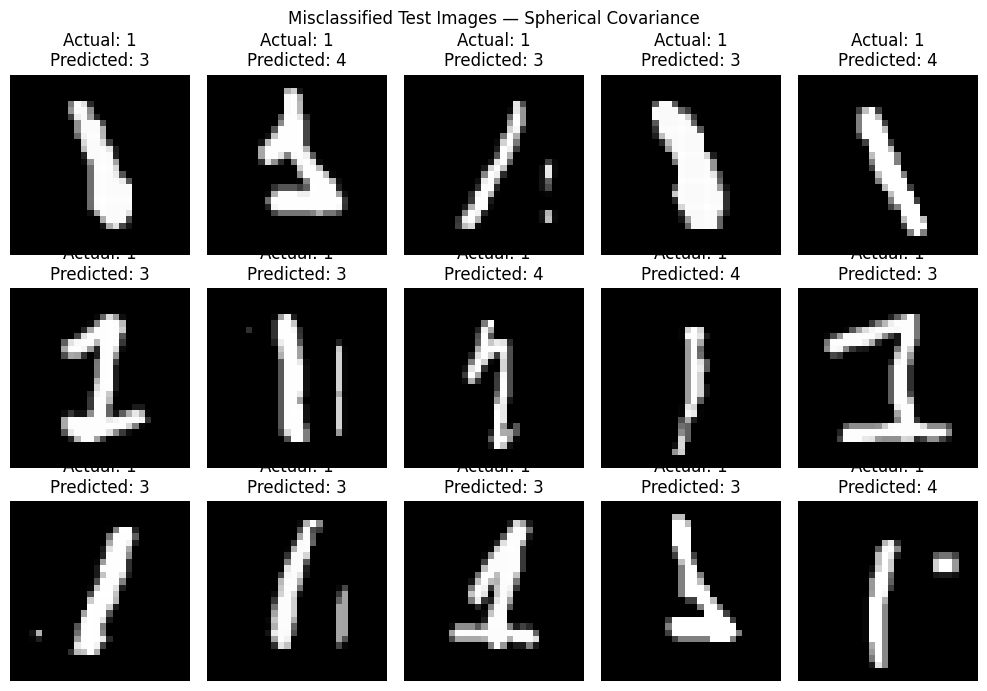

In [86]:
fig, axes = plt.subplots(3, 5, figsize=(10, 7))

preds = predictions_by_type["spherical"]
wrong_indices = np.where(preds != y_test_labels)[0]

for ax, idx in zip(axes.flat, wrong_indices[:15]):
    ax.imshow(X_test_images[idx].reshape(28, 28), cmap="gray")
    ax.set_title(
        f"Actual: {y_test_labels[idx]}\nPredicted: {preds[idx]}"
    )
    ax.axis("off")

for ax in axes.flat[len(wrong_indices[:15]):]:
    ax.axis("off")

plt.suptitle("Misclassified Test Images — Spherical Covariance")
plt.tight_layout()
plt.show()


In [99]:
results = []

for cov_type in covariance_types:
    preds = predictions_by_type[cov_type]

    accuracy = np.mean(y_test_labels == preds) * 100
    cm = matrices[cov_type]

    results.append({
        "Covariance Type": cov_type.capitalize(),
        "Accuracy (%)": round(accuracy, 2),
        "Correct Predictions": int(np.sum(preds == y_test_labels)),
        "Incorrect Predictions": int(np.sum(preds != y_test_labels))
    })

results_df = results
print("Covariance Type | Accuracy (%) | Correct Predictions | Incorrect Predictions")
print("-" * 75)

for result in results_df:
    print(
        result["Covariance Type"], "|",
        result["Accuracy (%)"], "|",
        result["Correct Predictions"], "|",
        result["Incorrect Predictions"]
    )

Covariance Type | Accuracy (%) | Correct Predictions | Incorrect Predictions
---------------------------------------------------------------------------
Spherical | 96.51 | 3018 | 109
Diag | 96.51 | 3018 | 109
Full | 96.51 | 3018 | 109
